# Разработка A/B-тестирования и анализ результатов

Вы работаете продуктовым аналитиком в компании, которая разрабатывает развлекательное приложение с функцией «бесконечной» ленты, как, например, в приложениях с короткими видео. В вашем приложении существует две модели монетизации: первая — ежемесячная платная подписка, которая позволяет пользователям смотреть ленту без рекламы, вторая — демонстрация рекламы для пользователей, которые ещё не оформили подписку.

Команда разработчиков рекомендательных систем создала новый алгоритм рекомендаций, который, по их мнению, будет показывать более интересный контент для каждого пользователя. Вас, как аналитика, просят помочь рассчитать параметры A/B-теста, который позволит проверить эту гипотезу, и проанализировать его результаты.

## Описание данных

Вы будете работать с тремя таблицами:

- `sessions_project_history.csv` — таблица с историческими данными по сессиям пользователей на период с 2025-08-15 по 2025-09-23. Путь к файлу: `/datasets/sessions_project_history.csv`.

- `sessions_project_test_part.csv` — таблица с данными за первый день проведения A/B-теста, то есть за 2025-10-14. Путь к файлу: `/datasets/sessions_project_test_part.csv`.

- `sessions_project_test.csv` — таблица с данными за весь период проведения A/B-теста, то есть с 2025-10-14 по 2025-11-02. Путь к файлу: `/datasets/sessions_project_test.csv`.

У этих таблиц почти совпадает структура и содержание колонок, различаются лишь периоды наблюдения.

Поля таблиц `sessions_project_history.csv`, `sessions_project_test.csv`, `sessions_project_test_part.csv`:

- `user_id` — идентификатор пользователя;

- `session_id` — идентификатор сессии в приложении;

- `session_date` — дата сессии;

- `session_start_ts` — дата и время начала сессии;

- `install_date` — дата установки приложения;

- `session_number` — порядковый номер сессии для конкретного пользователя;

- `registration_flag` — является ли пользователь зарегистрированным;

- `page_counter` — количество просмотренных страниц во время сессии;

- `region` — регион пользователя;

- `device` — тип устройства пользователя;

- `test_group` — тестовая группа (в таблице с историческими данными этого столбца нет).


## Что нужно сделать
Ваши задачи: рассчитать параметры теста, оценить корректность его проведения и проанализировать результаты эксперимента.

### 1. Работа с историческими данными (EDA)

#### 1.1. Загрузка исторических данных
На первом этапе поработайте с историческими данными приложения:

- Импортируйте библиотеку pandas.

- Считайте и сохраните в датафрейм `sessions_history` CSV-файл с историческими данными о сессиях пользователей `sessions_project_history.csv`.

Выведите на экран первые пять строк полученного датафрейма.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np 

from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

from math import ceil

from statsmodels.stats.proportion import proportions_ztest

In [2]:
sessions_history = pd.read_csv('/datasets/sessions_project_history.csv')
sessions_history.head(5)

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


#### 1.2. Знакомство с данными
- Для каждого уникального пользователя `user_id` рассчитайте количество уникальных сессий `session_id`.

- Выведите на экран все данные из таблицы `sessions_history` для одного пользователя с наибольшим количеством сессий. Если таких пользователей несколько, выберите любого из них.

- Изучите таблицу для одного пользователя, чтобы лучше понять логику формирования каждого столбца данных.

In [3]:
# кол-во уникальных сессий 
count_unique_session = sessions_history.groupby('user_id')['session_id'].nunique()

In [4]:
count_unique_session.sort_values(ascending=False)

user_id
10E0DEFC1ABDBBE0    10
6A73CB5566BB494D    10
8A60431A825D035B     9
D11541BAC141FB94     9
5BCFE7C4DCC148E9     9
                    ..
1DF13BB1953B3497     1
628502A3CE7E0A3C     1
1DEEF40DEFBD0C65     1
AC08479B7472C628     1
8A0882B6715D9EE5     1
Name: session_id, Length: 134039, dtype: int64

In [5]:
sessions_history[sessions_history['user_id'] == '10E0DEFC1ABDBBE0']

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
115558,10E0DEFC1ABDBBE0,B8F0423BBFFCF5DC,2025-08-14,2025-08-14 13:57:39,2025-08-14,1,0,4,CIS,Android
191751,10E0DEFC1ABDBBE0,87CA2FA549473837,2025-08-15,2025-08-15 16:42:10,2025-08-14,2,0,3,CIS,Android
239370,10E0DEFC1ABDBBE0,4ADD8011DCDCE318,2025-08-16,2025-08-16 19:53:21,2025-08-14,3,0,3,CIS,Android
274629,10E0DEFC1ABDBBE0,DF0FD0E09BF1F3D7,2025-08-17,2025-08-17 15:03:43,2025-08-14,4,0,1,CIS,Android
302501,10E0DEFC1ABDBBE0,3C221774B4DE6885,2025-08-18,2025-08-18 17:29:14,2025-08-14,5,0,4,CIS,Android
325557,10E0DEFC1ABDBBE0,031BD7A67048105B,2025-08-19,2025-08-19 13:23:55,2025-08-14,6,0,2,CIS,Android
345336,10E0DEFC1ABDBBE0,FF4315CF4AD4B100,2025-08-20,2025-08-20 19:31:54,2025-08-14,7,0,2,CIS,Android
377532,10E0DEFC1ABDBBE0,4045FEA0747203B4,2025-08-22,2025-08-22 17:54:13,2025-08-14,8,0,2,CIS,Android
403538,10E0DEFC1ABDBBE0,344B086C421C7F37,2025-08-24,2025-08-24 14:46:13,2025-08-14,9,0,2,CIS,Android
414743,10E0DEFC1ABDBBE0,054F20BA371E4C9D,2025-08-25,2025-08-25 18:36:41,2025-08-14,10,0,3,CIS,Android


#### 1.3. Анализ числа регистраций
Одна из важнейших метрик продукта — число зарегистрированных пользователей. Используя исторические данные, визуализируйте, как менялось число регистраций в приложении за время его существования. Пользователь считается зарегистрированным только в день совершения регистрации. Таким образом, вам необходимо проанализировать количество зарегистрированных активных пользователей за каждый день без накопления (аналог DAU, но для регистраций пользователей).

- Агрегируйте исторические данные и рассчитайте число уникальных пользователей и число зарегистрированных пользователей для каждого дня наблюдения. Для простоты считайте, что у пользователя в течение дня бывает одна сессия максимум и статус регистрации в течение одного дня не может измениться.

- Постройте линейные графики общего числа пользователей и общего числа зарегистрированных пользователей по дням. Отобразите их на одном графике.

- Постройте отдельный линейный график доли зарегистрированных пользователей от всех пользователей по дням.

- На обоих графиках должны быть заголовок, подписанные оси X и Y, сетка и легенда.

In [6]:
# считаем число уникальных пользователей 
unique_users = sessions_history.groupby('session_date')['user_id'].nunique()

In [7]:
# считаем число зарегестрированных пользователей 
registration_users = sessions_history[sessions_history['registration_flag'] == 1]
count_registration_users = registration_users.groupby('session_date')['user_id'].count()

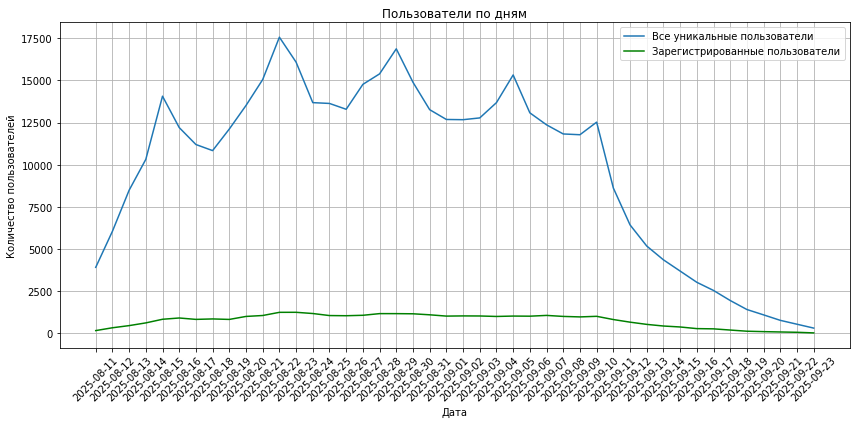

In [8]:
plt.figure(figsize=(12, 6))

plt.plot(unique_users.index, unique_users.values, 
         label='Все уникальные пользователи')

plt.plot(count_registration_users.index, count_registration_users.values, 
         label='Зарегистрированные пользователи',
         color = 'green')

plt.title('Пользователи по дням')
plt.xlabel('Дата')
plt.ylabel('Количество пользователей')
plt.legend()

plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
count_registration_users_per = count_registration_users / unique_users * 100

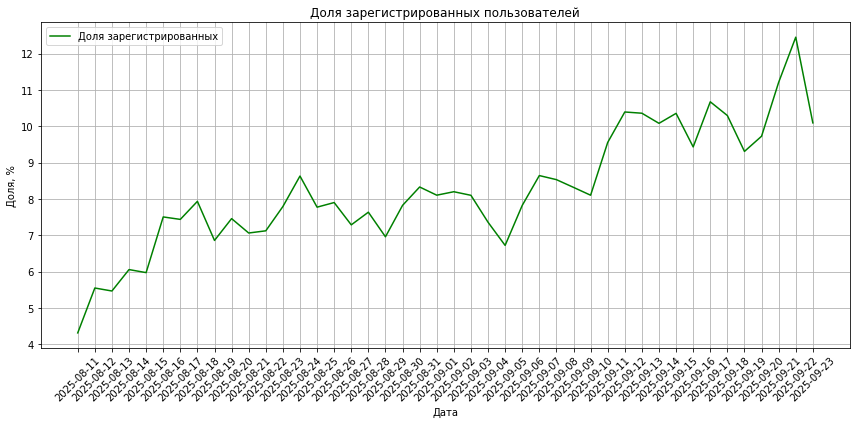

In [10]:
plt.figure(figsize=(12, 6))

plt.plot(count_registration_users_per.index,
         count_registration_users_per.values, 
         label='Доля зарегистрированных', 
         color='green')

plt.title('Доля зарегистрированных пользователей')
plt.xlabel('Дата')
plt.ylabel('Доля, %')
plt.legend()

plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Наблюдается небольшой скачкообразный рост с течением времени

#### 1.4. Анализ числа просмотренных страниц
Другая важная метрика продукта — число просмотренных страниц в приложении. Чем больше страниц просмотрено, тем сильнее пользователь увлечён контентом, а значит, выше шансы, что он зарегистрируется и оплатит подписку.

В рамках задания проанализируйте число просмотренных страниц во время первых сессий пользователей. Найдите количество первых сессий для каждого значения количества просмотренных страниц. Например: одну страницу просмотрели в 29 160 сессиях, две страницы — в 105 536 сессиях и так далее.

- Постройте столбчатую диаграмму, где по оси X будет число просмотренных страниц, по оси Y — количество сессий.

- На диаграмме должны быть заголовок, подписанные оси X и Y.

In [11]:
first_sessions = sessions_history[sessions_history['session_number'] == 1]
session_page_count = first_sessions.groupby('page_counter')['page_counter'].count()

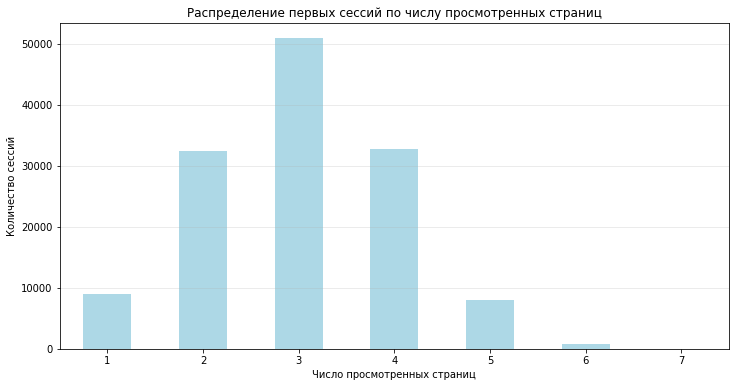

In [12]:
plt.figure(figsize=(12, 6))

session_page_count.plot(kind='bar', 
                     color='lightblue')

plt.title('Распределение первых сессий по числу просмотренных страниц')
plt.xlabel('Число просмотренных страниц')
plt.ylabel('Количество сессий')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

#### 1.5. Доля пользователей, просмотревших более четырёх страниц
Продуктовая команда продукта считает, что сессии, в рамках которых пользователь просмотрел 4 и более страниц, говорят об удовлетворённости контентом и алгоритмами рекомендаций. Этот показатель является важной прокси-метрикой для продукта.

- В датафрейме `sessions_history` создайте дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если было просмотрено меньше.

- Постройте график со средним значением доли успешных сессий от всех первых сессий пользователей. Данные нужно визуализировать по дням за весь период наблюдения.

In [13]:
# создаём новый столбец 
sessions_history['good_session'] = np.where(sessions_history['page_counter'] >= 4, 1, 0)

# отбираем первые сессии (все)
first_sessions_all = sessions_history[sessions_history['session_number'] == 1]

# отбираем первые сессии (успешные)
first_sessions_good = sessions_history[(sessions_history['session_number'] == 1) & (sessions_history['good_session'] == 1)]

# группируем 
good_by_date = first_sessions_good.groupby('session_date').size()
all_by_date = first_sessions_all.groupby('session_date').size()

# рассчитываем процент
success_rate = (good_by_date / all_by_date * 100)

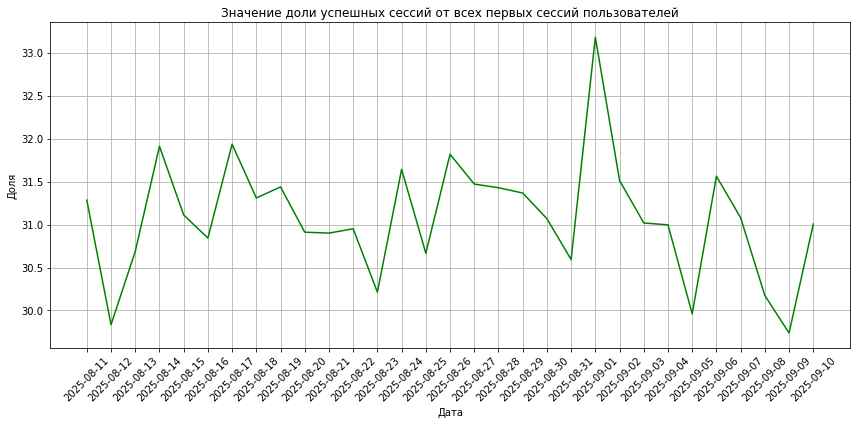

In [14]:
plt.figure(figsize=(12, 6))

plt.plot(success_rate.index,
         success_rate.values,
         color='green')

plt.title('Значение доли успешных сессий от всех первых сессий пользователей')
plt.xlabel('Дата')
plt.ylabel('Доля')

plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Наблюдается рост и падение скачками с чередованием (возможно зависит от  дня недели)

### 2. Подготовка к тесту
При планировании теста необходимо проделать несколько важных шагов:

- Определиться с целевой метрикой.

- Рассчитать необходимый размер выборки.

- Исходя из текущих значений трафика рассчитать необходимую длительность проведения теста.

#### 2.1. Расчёт размера выборки
В рамках курса вы уже рассчитывали размеры выборки и  использовали для этого онлайн-калькулятор. В этом задании предлагаем воспользоваться готовым кодом и рассчитать необходимое для вашего эксперимента количество пользователей.

Для этого установите в коде ниже следующие параметры:

- Уровень значимости — 0.05.

- Вероятность ошибки второго рода — 0.2.

- Мощность теста.

- Минимальный детектируемый эффект, или MDE, — 3%. Обратите внимание, что здесь нужно указать десятичную дробь, а не процент.

При расчёте размера выборки используйте метод `solve_power()` из класса `power.NormalIndPower` модуля `statsmodels.stats`.

Запустите ячейку и изучите полученное значение.

In [15]:
# Задайте параметры:
alpha = 0.05  # Уровень значимости
beta = 0.2  # Ошибка второго рода, часто 1 - мощность
power = 0.8  # Мощность теста
p = 0.3 # Базовый уровень доли
mde = 0.009  # Минимальный детектируемый эффект (относительный)
effect_size = proportion_effectsize(p, p + mde)

# Инициализируем класс NormalIndPower
power_analysis = NormalIndPower()

# Расчёт размера выборки
sample_size = power_analysis.solve_power(
    effect_size = effect_size,
    power = power,
    alpha = alpha,
    ratio = 1 # Равномерное распределение выборок
)

print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")
print(f"Общий размер выборки: {int(sample_size)*2}")

Необходимый размер выборки для каждой группы: 41040
Общий размер выборки: 82080


#### 2.2. Расчёт длительности A/B-теста

Используйте данные о количестве пользователей в каждой выборке и среднем количестве пользователей приложения. Рассчитайте длительность теста, разделив одно на другое.

- Рассчитайте среднее количество уникальных пользователей приложения в день.

- Определите длительность теста исходя из рассчитанного значения размера выборок и среднего дневного трафика приложения. Количество дней округлите в большую сторону.

In [16]:
# среднее количество пользователей приложения в день по историческим данным
avg_daily_users = int(sessions_history.groupby('session_date').agg({"user_id" : 'nunique'}).mean().iloc[0])

# расчитываем длительность теста в днях как отношение размера выборки к среднему числу пользователей
test_duration = ceil(2 * sample_size / avg_daily_users)

print(f"Расчитанная длительность А/Б теста при текущем уровене трафика в {avg_daily_users} пользователей в день, составит {test_duration} дня")

Расчитанная длительность А/Б теста при текущем уровене трафика в 9907 пользователей в день, составит 9 дня


### 3. Мониторинг А/В-теста

#### 3.1. Проверка распределения пользователей

A/B-тест успешно запущен, и уже доступны данные за первые три дня. На этом этапе нужно убедиться, что всё идёт хорошо: пользователи разделены правильным образом, а интересующие вас метрики корректно считаются.

- Считайте и сохраните в датафрейм `sessions_test_part` CSV-файл с историческими данными о сессиях пользователей `sessions_project_test_part.csv`.

- Рассчитайте количество уникальных пользователей в каждой из экспериментальных групп для одного дня наблюдения.

- Рассчитайте и выведите на экран процентную разницу в количестве пользователей в группах A и B. Постройте любую удобную визуализацию, на которой будет видно возможное различие двух групп.

Для расчёта процентной разницы воспользуйтесь формулой:
$$P = 100 \cdot  \frac{|A − B|}{A}$$

In [17]:
sessions_test_part = pd.read_csv('/datasets/sessions_project_test_part.csv')

In [18]:
sessions_test_part.head(5)

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group
0,3404844B53442747,B4901323BD537E45,2025-10-14,2025-10-14 19:28:49,2025-10-14,1,0,3,CIS,Android,B
1,3A2BF4D364E62D89,216FC619308F8788,2025-10-14,2025-10-14 21:11:04,2025-10-14,1,0,3,MENA,iPhone,A
2,79CDAE11E32B1597,EDFCE4AC1A504074,2025-10-14,2025-10-14 21:44:03,2025-10-14,1,0,3,CIS,iPhone,A
3,D6AF8D78297A931F,CF0AC0EEDE92C690,2025-10-14,2025-10-14 19:07:55,2025-10-14,1,0,4,CIS,PC,A
4,37E0CE723AE568E0,2E6ED45E8C86C4E9,2025-10-14,2025-10-14 15:39:44,2025-10-14,1,0,3,CIS,Mac,B


In [19]:
sessions_test_part_count_b = sessions_test_part[sessions_test_part['test_group'] == 'B']
b = sessions_test_part_count_b['user_id'].nunique()

In [20]:
sessions_test_part_count_a = sessions_test_part[sessions_test_part['test_group'] == 'A']
a = sessions_test_part_count_a['user_id'].nunique()

In [21]:
100 * (a - b)/a

0.7447528774542993

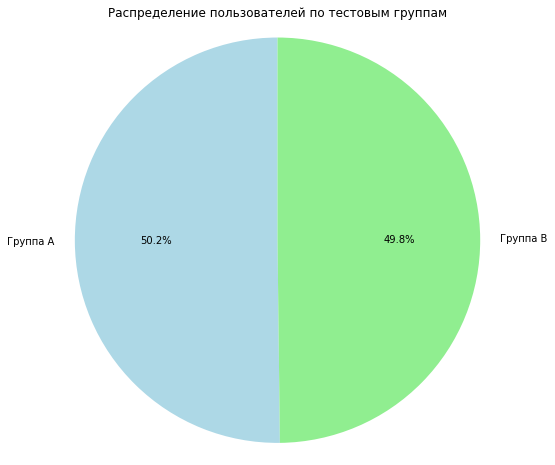

In [22]:
labels = ['Группа A', 'Группа B']
sizes = [a, b]
colors = ['lightblue', 'lightgreen']

plt.figure(figsize=(8, 8))
plt.pie(sizes, 
        labels=labels, 
        colors=colors, 
        autopct='%1.1f%%', 
        startangle=90)

plt.title('Распределение пользователей по тестовым группам')
plt.axis('equal')

plt.show()

#### 3.2. Проверка пересечений пользователей
Помимо проверки равенства количества пользователей в группах, полезно убедиться в том, что группы независимы. Для этого нужно убедиться, что никто из пользователей случайно не попал в обе группы одновременно.

- Рассчитайте количество пользователей, которые встречаются одновременно в группах A и B, или убедитесь, что таких нет.

In [23]:
group_a = sessions_test_part[sessions_test_part['test_group'] == 'A']['user_id']
group_b = sessions_test_part[sessions_test_part['test_group'] == 'B']['user_id']

intersection = list(set(group_a) & set(group_b))
print(intersection)

[]


#### 3.3. Равномерность разделения пользователей по устройствам
Полезно также убедиться в том, что пользователи равномерно распределены по всем доступным категориальным переменным — типам устройств и регионам.

Постройте две диаграммы:

- доля каждого типа устройства для пользователей из группы A,

- доля каждого типа устройства для пользователей из группы B.

Постарайтесь добавить на диаграммы все необходимые подписи, пояснения и заголовки, которые позволят сделать вывод о том, совпадает ли распределение устройств в группах A и B.


In [24]:
group_a = sessions_test_part[sessions_test_part['test_group'] == 'A']
group_b = sessions_test_part[sessions_test_part['test_group'] == 'B']

device_counts_a = group_a.groupby('device')['user_id'].nunique()
device_counts_b = group_b.groupby('device')['user_id'].nunique()

total_users_a = group_a['user_id'].nunique()
total_users_b = group_b['user_id'].nunique()

device_shares_a = (device_counts_a / total_users_a * 100).round(2)
device_shares_b = (device_counts_b / total_users_b * 100).round(2)

device_comparison = pd.DataFrame({
    'A': device_shares_a,
    'B': device_shares_b
})

print(device_comparison)

             A      B
device               
Android  44.41  45.57
Mac      10.56  10.10
PC       24.98  25.99
iPhone   20.04  18.35


In [25]:
group_aa = sessions_test_part[sessions_test_part['test_group'] == 'A']
group_bb = sessions_test_part[sessions_test_part['test_group'] == 'B']

region_counts_a = group_aa.groupby('region')['user_id'].nunique()
region_counts_b = group_bb.groupby('region')['user_id'].nunique()

total_users_a = group_aa['user_id'].nunique()
total_users_b = group_bb['user_id'].nunique()

region_shares_a = (region_counts_a / total_users_a * 100).round(2)
region_shares_b = (region_counts_b / total_users_b * 100).round(2)

region_comparison = pd.DataFrame({
    'A': region_shares_a,
    'B': region_shares_b
})

print(region_comparison)

            A     B
region             
CIS     43.60  44.0
EU      15.17  14.8
MENA    41.23  41.2


#### 3.4. Равномерность распределения пользователей по регионам
Теперь убедитесь, что пользователи равномерно распределены по регионам.

Постройте две диаграммы:

- доля каждого региона для пользователей из группы A,

- доля каждого региона для пользователей из группы B.

Постарайтесь добавить на диаграммы все необходимые подписи, пояснения и заголовки, которые позволят сделать вывод о том, совпадает ли распределение регионов в группах A и B. Постарайтесь использовать другой тип диаграммы, не тот, что в прошлом задании.

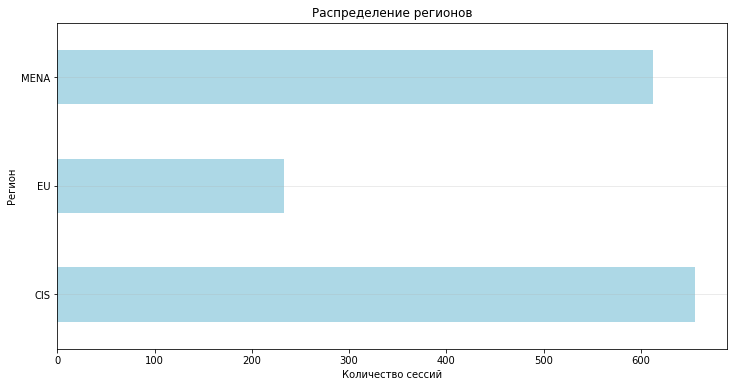

In [26]:
region_counts_a = sessions_test_part_count_a.groupby('region')['region'].count()

plt.figure(figsize=(12, 6))

region_counts_a.plot(kind='barh',
                     color='lightblue')

plt.title('Распределение регионов')
plt.ylabel('Регион')
plt.xlabel('Количество сессий')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

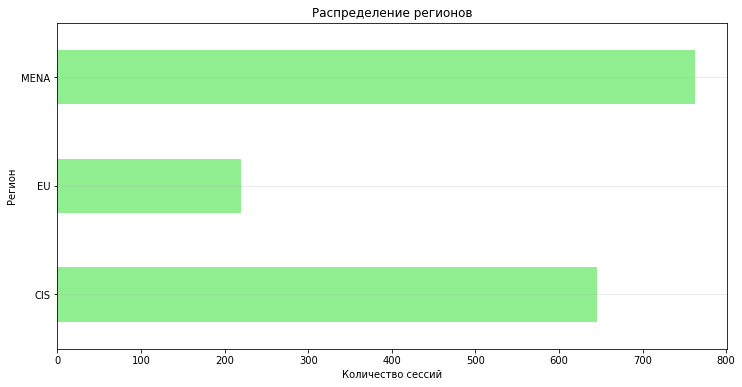

In [27]:
region_counts_b = sessions_test_part_count_b.groupby('region')['region'].count()

plt.figure(figsize=(12, 6))

region_counts_b.plot(kind='barh', 
                     color='lightgreen')

plt.title('Распределение регионов')
plt.ylabel('Регион')
plt.xlabel('Количество сессий')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

#### 3.5. Вывод после проверки A/B-теста

На основе проведённого анализа A/B-теста сформулируйте и запишите свои выводы. В выводе обязательно укажите:

- Было ли обнаружено различие в количестве пользователей в двух группах.

- Являются ли выборки независимыми. Было ли обнаружено пересечение пользователей из тестовой и контрольной групп.

- Сохраняется ли равномерное распределение пользователей тестовой и контрольной групп по категориальным переменным: устройствам и регионам.

Сделайте заключение: корректно ли проходит A/B-тест, или наблюдаются какие-либо нарушения.

****Выводы:****
- было обнаружено приемлимое различие в размерах выборок (отклоненеие меньше чем в 1%)
- пересечение пользователей из тестовой и контрольной групп не было обнаружено
- есть приемлемый перекос по устройствам и регионам 

### 4. Проверка результатов A/B-теста

A/B-тест завершён, и у вас есть результаты за все дни проведения эксперимента. Необходимо убедиться в корректности теста и верно интерпретировать результаты.

#### 4.1. Получение результатов теста и подсчёт основной метрики

- Считайте и сохраните в датафрейм `sessions_test` CSV-файл с историческими данными о сессиях пользователей `sessions_project_test.csv`.

- В датафрейме `sessions_test` создайте дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если просмотрено меньше.

In [28]:
sessions_test = pd.read_csv('/datasets/sessions_project_test.csv')

In [29]:
sessions_test['good_session'] = np.where(sessions_test['page_counter'] >= 4, 1, 0)
sessions_test.head(5)

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group,good_session
0,6DAE3B3654DA738E,C69249E26E58F6E2,2025-10-26,2025-10-26 18:15:05,2025-10-16,3,0,3,MENA,Android,A,0
1,0A3FE5D1DD59110A,66D66D7C9F5181B7,2025-10-21,2025-10-21 17:04:53,2025-10-15,2,1,2,CIS,Android,B,0
2,2041F1D7AA740B88,50DE51D42215E74C,2025-10-23,2025-10-23 17:39:29,2025-10-19,3,0,2,MENA,Android,A,0
3,43D7585009168086,5763C0C353C22263,2025-10-24,2025-10-24 15:01:57,2025-10-18,4,0,1,CIS,iPhone,B,0
4,15AD68B14D62D88C,B1AD09F93C1053BC,2025-10-17,2025-10-17 17:34:39,2025-10-17,1,0,2,MENA,Android,B,0


#### 4.2 Формулировка нулевой и альтернативной гипотез. Определение целевой, прокси- и барьерных метрик


Перед тем как проводить А/B-тест, необходимо сформулировать нулевую и альтернативную гипотезы. Напомним изначальное условие: команда разработчиков рекомендательных систем создала новый алгоритм, который, по их мнению, будет показывать более интересный контент для каждого пользователя.

Подумайте, о какой метрике идёт речь и как она будет учтена в формулировке гипотез. Сформулируйте нулевую и альтернативную гипотезы.

Не забывайте, что до проведения эксперимента важно выделять и отслеживать изменение прокси- и барьерных метрик. В имеющихся у вас данных о проведении эксперимента этих метрик нет. Подумайте, какие показатели вы бы выбрали в качестве прокси- и барьерных метрик, если бы проводили этот эксперимент самостоятельно.

**Основная метрика:** Время проведённое на сайте 

H_0: Новый алгоритм **не влияет** на количество страниц просматриваемых пользователями (M0 = M1)

H_1: Новый алгоритм **увеличивает** количество страниц просматриваемых пользователями (M0 < M1)

**Прокси метрика:**
 
Время проведённое на сайте 

**Барьерная метрика:** 

Отток пользователей (кол-во)

Технические сбои (кол-во)

#### 4.3. Сравнение доли успешных сессий

Перейдем к анализу ключевой метрики — доле успешных первых сессий.

Используйте созданный на первом шаге задания столбец `good_session` и рассчитайте долю успешных первых сессий для выборок A и B, а также разницу в этом показателе. Полученный вывод отобразите на экране.

In [30]:
first_sessions = sessions_test[sessions_test['session_number'] == 1]

test_a = first_sessions[first_sessions['test_group'] == 'A']

proportion_a = (test_a['good_session'] == 1).sum() / len(test_a)
len_a = len(test_a)
success_a = (test_a['good_session'] == 1).sum()

print(f"Доля успешных первых сессий для А: {proportion_a:.3f} ")

Доля успешных первых сессий для А: 0.316 


In [31]:
first_sessions = sessions_test[sessions_test['session_number'] == 1]

test_b = first_sessions[first_sessions['test_group'] == 'B']

proportion_b = (test_b['good_session'] == 1).sum() / len(test_b)
len_b = len(test_b)
success_b = (test_b['good_session'] == 1).sum()

print(f"Доля успешных первых сессий для B: {proportion_b:.3f} ")

Доля успешных первых сессий для B: 0.315 


In [32]:
print(f"Размер выборки А: {len_a}")
print(f"Количество успехов для А: {success_a}")

print(f"Размер выборки B: {len_b}")
print(f"Количество успехов для B: {success_b}")

Размер выборки А: 15162
Количество успехов для А: 4787
Размер выборки B: 15416
Количество успехов для B: 4851


In [33]:
print(f" Разница: {proportion_a -  proportion_b}")

 Разница: 0.0010504523811919464


#### 4.4. Насколько статистически значимо изменение ключевой метрики

На предыдущем шаге вы убедились, что количество успешных сессий в тестовой выборке примерно на 1.1% выше, чем в контрольной, но делать выводы только на основе этого значения будет некорректно. Для принятия решения всегда необходимо отвечать на вопрос: является ли это изменение статистически значимым.

- Используя статистический тест, рассчитайте, является ли изменение в метрике доли успешных сессий статистически значимым.

- Выведите на экран полученное значение p-value и свои выводы о статистической значимости. Напомним, что уровень значимости в эксперименте был выбран на уровне 0.05.

In [34]:
n_a, n_b = 15162, 15416 # размеры выборок A и B 
m_a, m_b = 4787, 4851 # количество успехов в выборках A и B 

p_a, p_b = m_a/n_a, m_b/n_b # доли успехов

if (p_a*n_a > 10)and((1-p_a)*n_a > 10)and(p_b*n_b > 10)and((1-p_b)*n_b > 10):
    print('Предпосылка о достаточном количестве данных выполняется')
else:
    print('Предпосылка о достаточном количестве данных НЕ выполняется')

alpha = 0.05 # значимость

stat_ztest, p_value_ztest = proportions_ztest(
    [m_a, m_b],
    [n_a, n_b],
    alternative='smaller' # проверяем что В больше чем А
)

if p_value_ztest > alpha:
    print(f'pvalue={p_value_ztest} > {alpha}')
    print('Не можем отклонить нулевую гипотезу, принимаем H0')
else:
    print(f'pvalue={p_value_ztest} < {alpha}')
    print('Отклоняем нулевую гипотезу, принимаем H1')

Предпосылка о достаточном количестве данных выполняется
pvalue=0.5783523649187868 > 0.05
Не можем отклонить нулевую гипотезу, принимаем H0


#### 4.5. Вывод по результатам A/B-эксперимента

На основе проведённого анализа результатов теста сформулируйте и запишите свои выводы для команды разработки приложения. В выводе обязательно укажите:

- Характеристики проведённого эксперимента, количество задействованных пользователей и длительность эксперимента.

- Повлияло ли внедрение нового алгоритма рекомендаций на рост ключевой метрики и как.

- Каким получилось значение p-value для оценки статистической значимости выявленного эффекта.

- Стоит ли внедрять нововведение в приложение.

**Вывод:**

При проведении А/В теста была задействована выборка в размере `30578 пользователей`, длительность теста  составила `9 дней`

По итогам доля успешных сессий для выборки А (контрольная) составила ~ 0.316, для B (тестовая) ~ 0.315, что `говорит о отрицательном влиянии.`

Результаты z-теста пропорций `не подтвердили` статистическую значимость изменений на уровне а = 0.05 при `pvalue = 0.578`

`Итог: не стоит внедрять нововведение`